Les données

In [1]:
from google.colab import files
import pandas as pd
import io

print("📂 Choisis ton fichier COMPLET...")
uploaded2 = files.upload()

df_complet = pd.read_csv(io.BytesIO(list(uploaded2.values())[0]), dayfirst=True, sep=';')

# Vérifier les colonnes
print("Colonnes trouvées :", list(df_complet.columns))
print(f"Dimensions : {df_complet.shape}")

print(df_complet['breakdown_flag'].value_counts())
print(f"\nTotal : {len(df_complet)} lignes")
print(f"% pannes : {df_complet['breakdown_flag'].mean()*100:.1f}%")

📂 Choisis ton fichier COMPLET...


Saving DataPiece.csv to DataPiece.csv
Colonnes trouvées : ['transaction_date', 'machine_type', 'plant_code', 'part_family', 'criticality', 'uom', 'unit_cost_inr', 'qty_issued', 'temp_bearing_degC', 'temp_motor_degC', 'vibration_h_mms', 'vibration_v_mms', 'oil_pressure_bar', 'load_pct', 'shaft_rpm', 'power_consumption_kw', 'breakdown_flag']
Dimensions : (219000, 17)
breakdown_flag
0    197364
1     21636
Name: count, dtype: int64

Total : 219000 lignes
% pannes : 9.9%


In [2]:
df_complet.isnull().sum()

,0
transaction_date,0
machine_type,0
plant_code,0
part_family,0
criticality,0
uom,0
unit_cost_inr,0
qty_issued,0
temp_bearing_degC,0
temp_motor_degC,0


In [4]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELLULE 1 — Importer TOUTES les bibliothèques
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

In [7]:



print("✅ Toutes les bibliothèques importées !")
print(f"   → TensorFlow version : {tf.__version__}")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELLULE 2 — Uploader le fichier UNE SEULE FOIS ✅
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

from google.colab import files

#print("📂 Choisis ton fichier DataPiece.csv ...")
#uploaded = files.upload()
#print("✅ Fichier uploadé avec succès !")


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELLULE 3 — Charger et explorer les données UNE SEULE FOIS ✅
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

#df_original = pd.read_csv(io.BytesIO(list(uploaded.values())[0]), dayfirst=True, sep=';')

# --- Rééquilibrer intelligemment ---
df_class0 = df_complet[df_complet['breakdown_flag'] == 0]
df_class1 = df_complet[df_complet['breakdown_flag'] == 1]

print(f"   → Classe 0 (pas de panne) : {len(df_class0)} lignes")
print(f"   → Classe 1 (panne)        : {len(df_class1)} lignes")

df_complet = pd.concat([
    df_class0.sample(n=len(df_class1)*3, random_state=42),  # 64 908 non-pannes
    df_class1                                                 # 21 636 pannes
]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"   → Dataset final : {len(df_complet)} lignes")
print(f"   → Ratio pannes  : {df_complet['breakdown_flag'].mean()*100:.1f}%")

print("=" * 55)
print("  APERÇU DES DONNÉES - DataPiece.csv")
print("=" * 55)
print(f"\n📊 Dimensions : {df_complet.shape[0]} lignes x {df_complet.shape[1]} colonnes")
print("\n📋 Les 5 premières lignes :")
display(df_complet.head())
print("\n📋 Informations sur les colonnes :")
print(df_complet.info())
print("\n📋 Statistiques générales :")
display(df_complet.describe())
print("\n🔎 Valeurs manquantes par colonne :")
print(df_complet.isnull().sum())
print("\n📌 Noms de toutes les colonnes :")
print(list(df_complet.columns))


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# CELLULE 4 — Préparer les données UNE SEULE FOIS ✅
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

colonne_cible = "breakdown_flag"

df = df_complet.copy()
df = df.dropna()
print(f"   → Après nettoyage : {df.shape[0]} lignes restantes")

# --- Traitement de la date ---
df['transaction_date'] = pd.to_datetime(df['transaction_date'], dayfirst=True)
df['mois']   = df['transaction_date'].dt.month
df['saison'] = df['mois'].apply(lambda m:
    1 if m in [12, 1, 2] else
    2 if m in [3, 4, 5]  else
    3 if m in [6, 7, 8]  else 4
)
df = df.drop(columns=['transaction_date'])
print("   → 'transaction_date' → 'mois' + 'saison' ✅")

# --- Séparer X et y ---
X = df.drop(columns=[colonne_cible])
y = df[colonne_cible]

# --- Encoder les colonnes textuelles ---
le = LabelEncoder()
for col in X.select_dtypes(include=['object']).columns:
    X[col] = le.fit_transform(X[col].astype(str))
    print(f"   → Colonne '{col}' encodée ✅")

noms_classes = list(y.unique()) if y.dtype == 'object' else [str(c) for c in np.unique(y)]
if y.dtype == 'object':
    y = le.fit_transform(y.astype(str))

# --- Split train/test ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"\n   → Train : {X_train.shape[0]} exemples | Test : {X_test.shape[0]} exemples")

# --- Version normalisée (pour SVM, KNN, ANN) ---
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# --- Version one-hot (pour ANN uniquement) ---
nb_classes  = len(np.unique(y))
y_train_cat = to_categorical(y_train, num_classes=nb_classes)
y_test_cat  = to_categorical(y_test,  num_classes=nb_classes)

print(f"   → Normalisation : ✅  |  One-hot : ✅")
print(f"\n✅ Données prêtes pour tous les algorithmes !")
print(f"   (X_train, X_test sans normalisation → DT, RF)")
print(f"   (X_train_sc, X_test_sc normalisés   → SVM, KNN, ANN)")


✅ Toutes les bibliothèques importées !
   → TensorFlow version : 2.20.0
   → Classe 0 (pas de panne) : 197364 lignes
   → Classe 1 (panne)        : 21636 lignes
   → Dataset final : 86544 lignes
   → Ratio pannes  : 25.0%
  APERÇU DES DONNÉES - DataPiece.csv

📊 Dimensions : 86544 lignes x 17 colonnes

📋 Les 5 premières lignes :


,transaction_date,machine_type,plant_code,part_family,criticality,uom,unit_cost_inr,qty_issued,temp_bearing_degC,temp_motor_degC,vibration_h_mms,vibration_v_mms,oil_pressure_bar,load_pct,shaft_rpm,power_consumption_kw,breakdown_flag
0,25/05/2022,Hydraulic Press,CHN-02,Lubrication,C,EA,18,0,67.1,75.6,4.111,3.122,6.62,83.2,942,75.30,0
1,15/03/2022,Hydraulic Press,CHN-02,Bearing,A,EA,2100,0,66.0,71.5,4.140,3.086,6.96,80.1,941,72.40,0
2,17/12/2022,CNC Lathe,PUN-01,Lubrication,C,CTG,210,0,65.7,66.6,4.590,3.647,3.93,63.2,1707,10.92,0
3,03/09/2024,EOT Crane,PUN-01,Electrical,B,SET,430,0,66.6,76.6,3.203,2.324,3.61,58.5,693,18.66,0
4,15/04/2024,EOT Crane,DHR-03,Seal & Gasket,C,EA,12,0,67.5,63.2,3.215,2.336,5.94,79.1,747,18.00,0



📋 Informations sur les colonnes :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86544 entries, 0 to 86543
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   transaction_date      86544 non-null  object 
 1   machine_type          86544 non-null  object 
 2   plant_code            86544 non-null  object 
 3   part_family           86544 non-null  object 
 4   criticality           86544 non-null  object 
 5   uom                   86544 non-null  object 
 6   unit_cost_inr         86544 non-null  int64  
 7   qty_issued            86544 non-null  int64  
 8   temp_bearing_degC     86544 non-null  float64
 9   temp_motor_degC       86544 non-null  float64
 10  vibration_h_mms       86544 non-null  float64
 11  vibration_v_mms       86544 non-null  float64
 12  oil_pressure_bar      86544 non-null  float64
 13  load_pct              86544 non-null  float64
 14  shaft_rpm             86544 non-nul

,unit_cost_inr,qty_issued,temp_bearing_degC,temp_motor_degC,vibration_h_mms,vibration_v_mms,oil_pressure_bar,load_pct,shaft_rpm,power_consumption_kw,breakdown_flag
count,86544.000000,86544.000000,86544.000000,86544.000000,86544.000000,86544.000000,86544.000000,86544.000000,86544.000000,86544.000000,86544.000000
mean,839.226578,0.125185,65.132686,71.098912,3.889036,2.915077,5.023564,69.011268,1555.652708,26.875337,0.250000
std,803.208084,0.448518,4.965419,6.880559,1.368495,1.043984,0.954454,12.045971,779.569990,19.411525,0.433015
min,12.000000,0.000000,43.500000,49.800000,0.671000,0.401000,3.300000,34.200000,654.000000,4.430000,0.000000
25%,210.000000,0.000000,63.800000,65.000000,3.097000,2.300000,4.130000,59.400000,932.000000,13.447500,0.000000
50%,670.000000,0.000000,66.400000,71.400000,3.627000,2.746000,4.940000,70.000000,1438.000000,16.880000,0.000000
75%,1100.000000,0.000000,68.300000,77.000000,4.399000,3.310000,5.470000,79.500000,1812.000000,39.730000,0.250000
max,3200.000000,7.000000,73.500000,88.400000,13.305000,10.088000,7.390000,95.400000,2980.000000,82.500000,1.000000



🔎 Valeurs manquantes par colonne :
transaction_date        0
machine_type            0
plant_code              0
part_family             0
criticality             0
uom                     0
unit_cost_inr           0
qty_issued              0
temp_bearing_degC       0
temp_motor_degC         0
vibration_h_mms         0
vibration_v_mms         0
oil_pressure_bar        0
load_pct                0
shaft_rpm               0
power_consumption_kw    0
breakdown_flag          0
dtype: int64

📌 Noms de toutes les colonnes :
['transaction_date', 'machine_type', 'plant_code', 'part_family', 'criticality', 'uom', 'unit_cost_inr', 'qty_issued', 'temp_bearing_degC', 'temp_motor_degC', 'vibration_h_mms', 'vibration_v_mms', 'oil_pressure_bar', 'load_pct', 'shaft_rpm', 'power_consumption_kw', 'breakdown_flag']
   → Après nettoyage : 86544 lignes restantes
   → 'transaction_date' → 'mois' + 'saison' ✅
   → Colonne 'machine_type' encodée ✅
   → Colonne 'plant_code' encodée ✅
   → Colonne 'part_family'

Code de l'algorithme SVM

   → Taille pour SVM : 20000 lignes
   → Ratio pannes    : 25.0%
🤖 Entraînement du modèle SVM en cours...
✅ Modèle SVM entraîné avec succès !
       RÉSULTATS DU MODÈLE SVM
  🎯 Accuracy  : 58.78%
  🔍 Precision : 74.22%
  📡 Recall    : 58.78%
  ⚖️  F1-Score : 61.35%
              precision    recall  f1-score   support

           0       0.87      0.53      0.66     12965
           1       0.35      0.77      0.48      4344

    accuracy                           0.59     17309
   macro avg       0.61      0.65      0.57     17309
weighted avg       0.74      0.59      0.61     17309



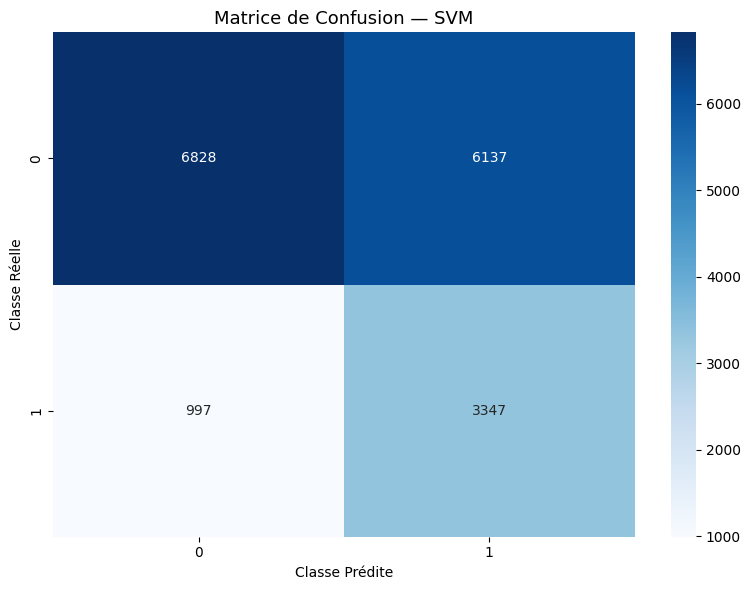

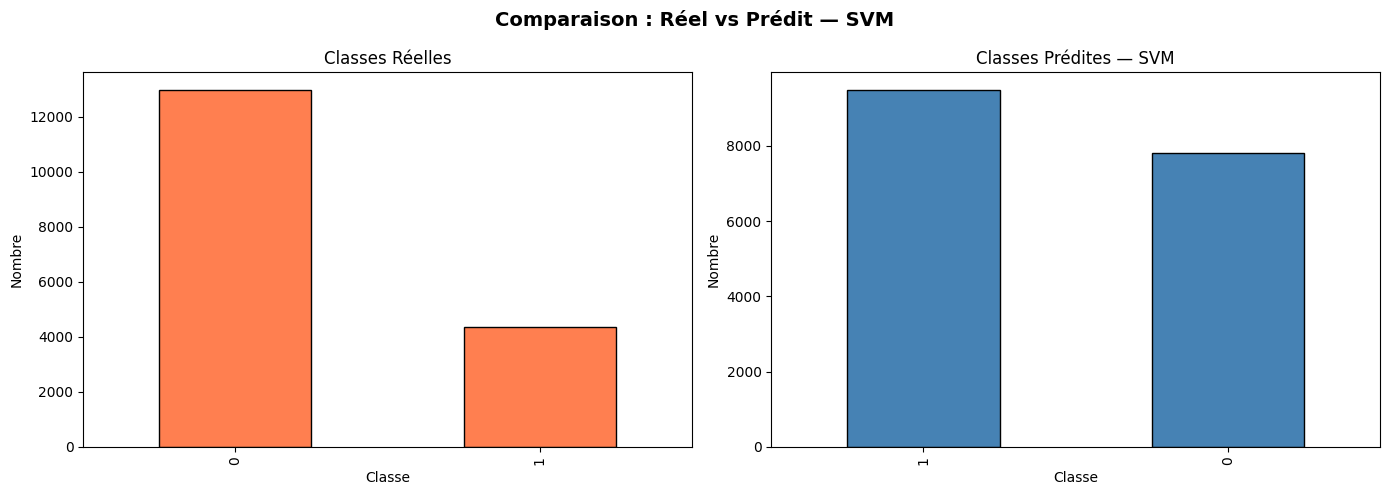

✅ SVM terminé !


In [8]:
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ███████████████████  SVM  ██████████████████████████████████████
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# le svm est le seul qui est lent

# CELLULE 5 — Entraîner le modèle SVM (sous-ensemble pour la vitesse)

from sklearn.model_selection import train_test_split

# Réduire le train à 20 000 lignes (stratifié = même ratio pannes)
X_train_sc_svm, _, y_train_svm, _ = train_test_split(
    X_train_sc, y_train,
    train_size=20000,
    random_state=42,
    stratify=y_train
)

print(f"   → Taille pour SVM : {X_train_sc_svm.shape[0]} lignes")
print(f"   → Ratio pannes    : {y_train_svm.mean()*100:.1f}%")

print("🤖 Entraînement du modèle SVM en cours...")
modele_svm = SVC(kernel='rbf', C=1.0, gamma='scale',
                 class_weight='balanced',  # ← ajout ici
                 random_state=42)
modele_svm.fit(X_train_sc_svm, y_train_svm)
print("✅ Modèle SVM entraîné avec succès !")


# CELLULE 6 — Évaluer le SVM

y_pred_svm = modele_svm.predict(X_test_sc)

acc_svm  = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm, average='weighted')
rec_svm  = recall_score(y_test, y_pred_svm, average='weighted')
f1_svm   = f1_score(y_test, y_pred_svm, average='weighted')

print("=" * 50)
print("       RÉSULTATS DU MODÈLE SVM")
print("=" * 50)
print(f"  🎯 Accuracy  : {acc_svm  * 100:.2f}%")
print(f"  🔍 Precision : {prec_svm * 100:.2f}%")
print(f"  📡 Recall    : {rec_svm  * 100:.2f}%")
print(f"  ⚖️  F1-Score : {f1_svm   * 100:.2f}%")
print("=" * 50)
print(classification_report(y_test, y_pred_svm))


# CELLULE 7 — Matrice de confusion SVM

cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Matrice de Confusion — SVM', fontsize=13)
plt.xlabel('Classe Prédite'); plt.ylabel('Classe Réelle')
plt.tight_layout(); plt.savefig("matrice_confusion_svm.png", dpi=150); plt.show()


# CELLULE 8 — Réel vs Prédit SVM

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(y_test).value_counts().plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Classes Réelles'); axes[0].set_xlabel('Classe'); axes[0].set_ylabel('Nombre')
pd.Series(y_pred_svm).value_counts().plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title('Classes Prédites — SVM'); axes[1].set_xlabel('Classe'); axes[1].set_ylabel('Nombre')
plt.suptitle('Comparaison : Réel vs Prédit — SVM', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("comparaison_svm.png", dpi=150); plt.show()
print("✅ SVM terminé !")


Code de l'algorithme KNN

In [ ]:
!pip install imbalanced-learn -q

🔍 Recherche du meilleur K...
✅ Meilleur K : 18  (Accuracy = 74.16%)


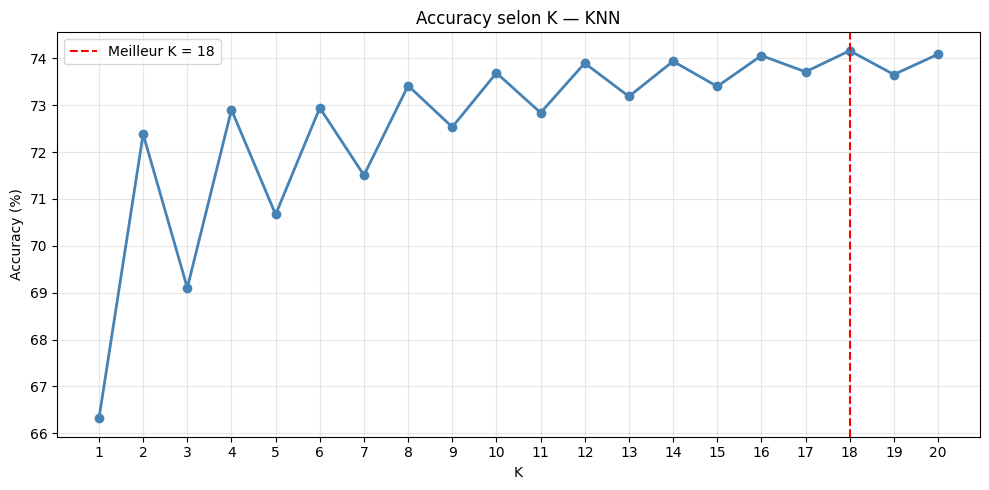

   → Après SMOTE : 103886 lignes, ratio pannes : 50.0%


In [ ]:

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ███████████████████  KNN  ██████████████████████████████████████
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# CELLULE 9 — Trouver le meilleur K

print("🔍 Recherche du meilleur K...")
liste_k = range(1, 21)
accs_k  = []
for k in liste_k:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train_sc, y_train)
    accs_k.append(accuracy_score(y_test, m.predict(X_test_sc)))

meilleur_k = liste_k[np.argmax(accs_k)]
print(f"✅ Meilleur K : {meilleur_k}  (Accuracy = {max(accs_k)*100:.2f}%)")

plt.figure(figsize=(10, 5))
plt.plot(liste_k, [a*100 for a in accs_k], marker='o', color='steelblue', linewidth=2)
plt.axvline(x=meilleur_k, color='red', linestyle='--', label=f'Meilleur K = {meilleur_k}')
plt.title("Accuracy selon K — KNN"); plt.xlabel("K"); plt.ylabel("Accuracy (%)")
plt.xticks(liste_k); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("choix_k_knn.png", dpi=150); plt.show()


# CELLULE 10 — Entraîner et évaluer KNN

from imblearn.over_sampling import SMOTE

# SMOTE : générer des exemples synthétiques de pannes
sm = SMOTE(random_state=42)
X_train_sc_knn, y_train_knn = sm.fit_resample(X_train_sc, y_train)
print(f"   → Après SMOTE : {X_train_sc_knn.shape[0]} lignes, ratio pannes : {y_train_knn.mean()*100:.1f}%")

modele_knn = KNeighborsClassifier(n_neighbors=meilleur_k, weights='distance')
modele_knn.fit(X_train_sc_knn, y_train_knn)
y_pred_knn = modele_knn.predict(X_test_sc)

acc_knn  = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn, average='weighted')
rec_knn  = recall_score(y_test, y_pred_knn, average='weighted')
f1_knn   = f1_score(y_test, y_pred_knn, average='weighted')

print("=" * 50)
print("       RÉSULTATS DU MODÈLE KNN")
print("=" * 50)
print(f"  🎯 Accuracy  : {acc_knn  * 100:.2f}%")
print(f"  🔍 Precision : {prec_knn * 100:.2f}%")
print(f"  📡 Recall    : {rec_knn  * 100:.2f}%")
print(f"  ⚖️  F1-Score : {f1_knn   * 100:.2f}%")
print("=" * 50)
print(classification_report(y_test, y_pred_knn))


# CELLULE 11 — Matrice de confusion KNN

cm_knn = confusion_matrix(y_test, y_pred_knn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Matrice de Confusion — KNN', fontsize=13)
plt.xlabel('Classe Prédite'); plt.ylabel('Classe Réelle')
plt.tight_layout(); plt.savefig("matrice_confusion_knn.png", dpi=150); plt.show()


# CELLULE 12 — Réel vs Prédit KNN

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(y_test).value_counts().plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Classes Réelles'); axes[0].set_xlabel('Classe'); axes[0].set_ylabel('Nombre')
pd.Series(y_pred_knn).value_counts().plot(kind='bar', ax=axes[1], color='mediumseagreen', edgecolor='black')
axes[1].set_title('Classes Prédites — KNN'); axes[1].set_xlabel('Classe'); axes[1].set_ylabel('Nombre')
plt.suptitle('Comparaison : Réel vs Prédit — KNN', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("comparaison_knn.png", dpi=150); plt.show()
print("✅ KNN terminé !")


Code de l'algorithme Decision Tree

🔍 Recherche de la meilleure profondeur...
✅ Meilleure profondeur : 15  (F1 = 60.02%)


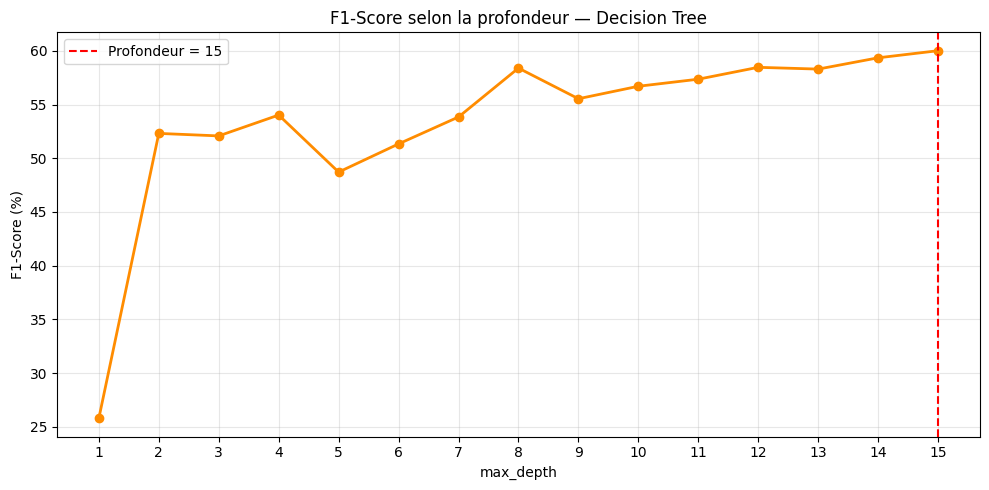

    RÉSULTATS DU MODÈLE DECISION TREE
  🎯 Accuracy  : 57.43%
  🔍 Precision : 73.45%
  📡 Recall    : 57.43%
  ⚖️  F1-Score : 60.02%
              precision    recall  f1-score   support

           0       0.87      0.51      0.64     12965
           1       0.34      0.76      0.47      4344

    accuracy                           0.57     17309
   macro avg       0.60      0.64      0.56     17309
weighted avg       0.73      0.57      0.60     17309



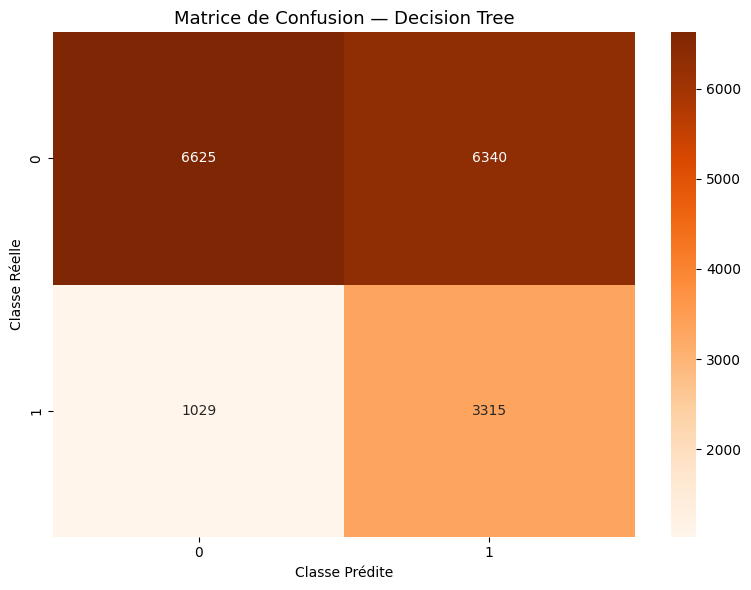

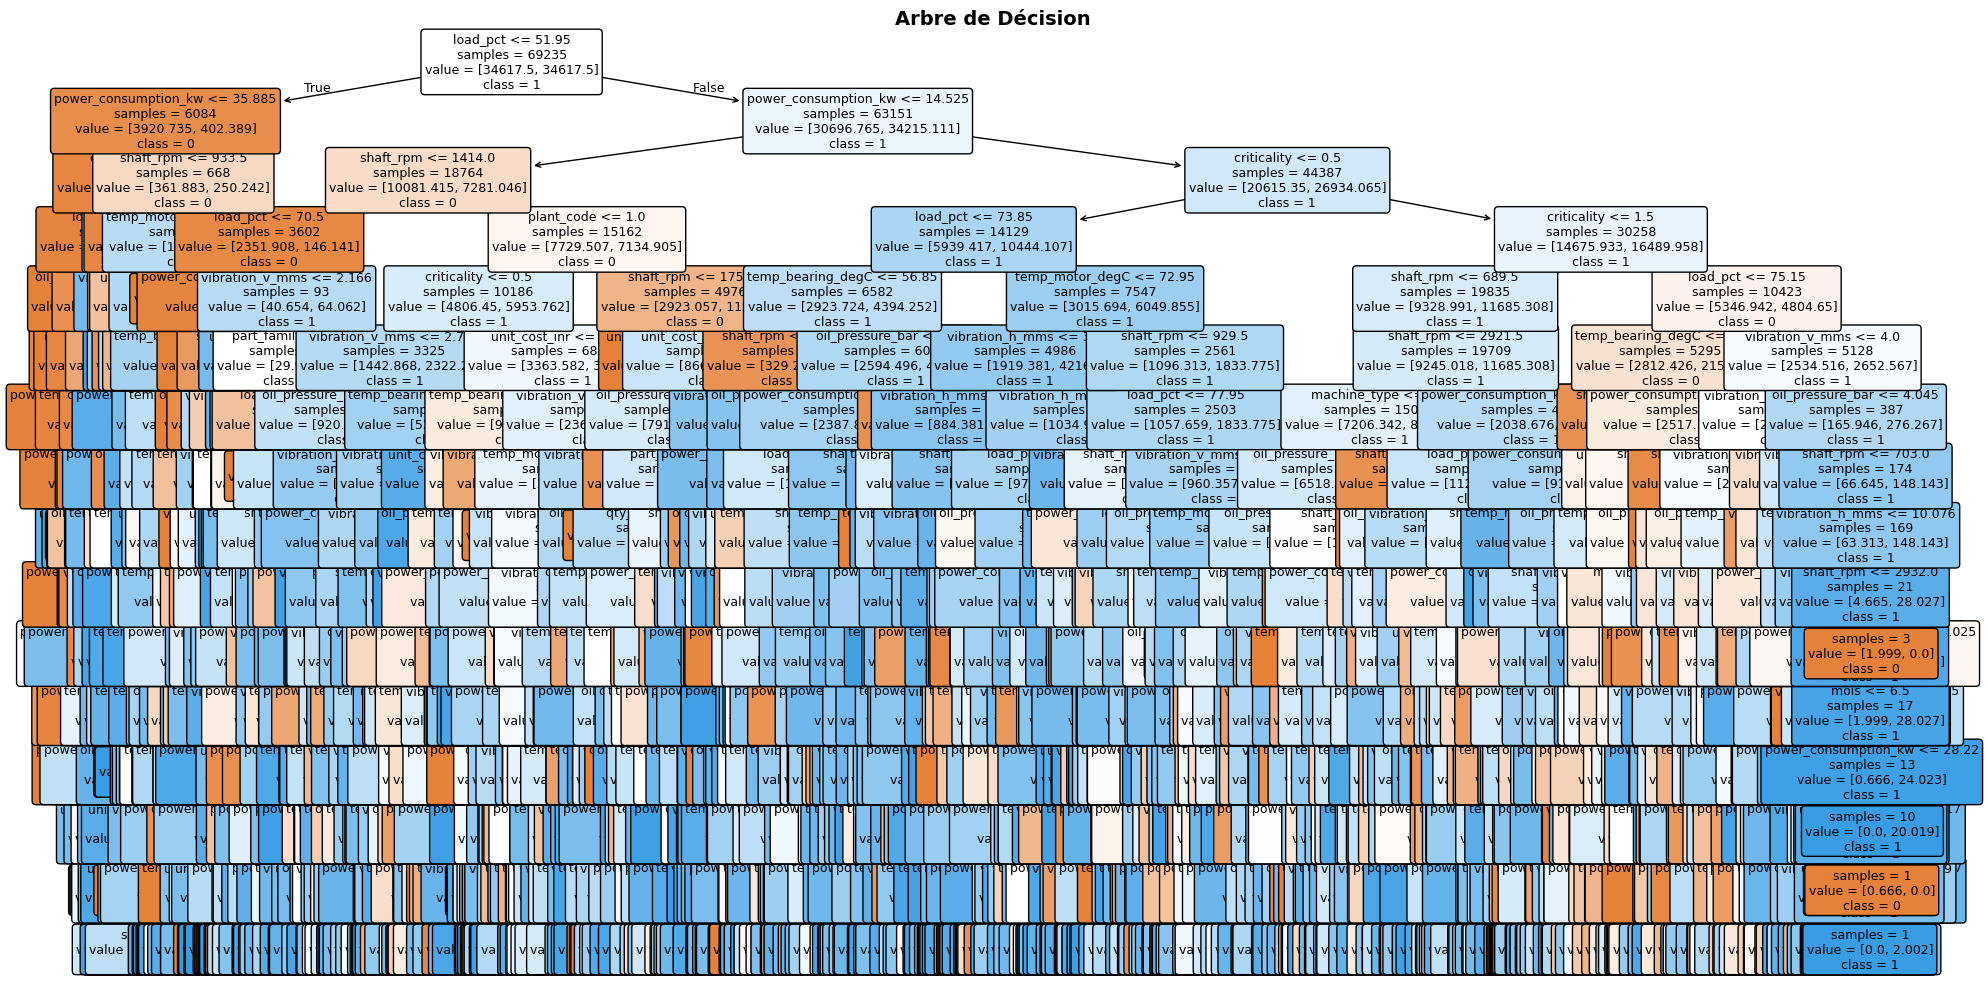

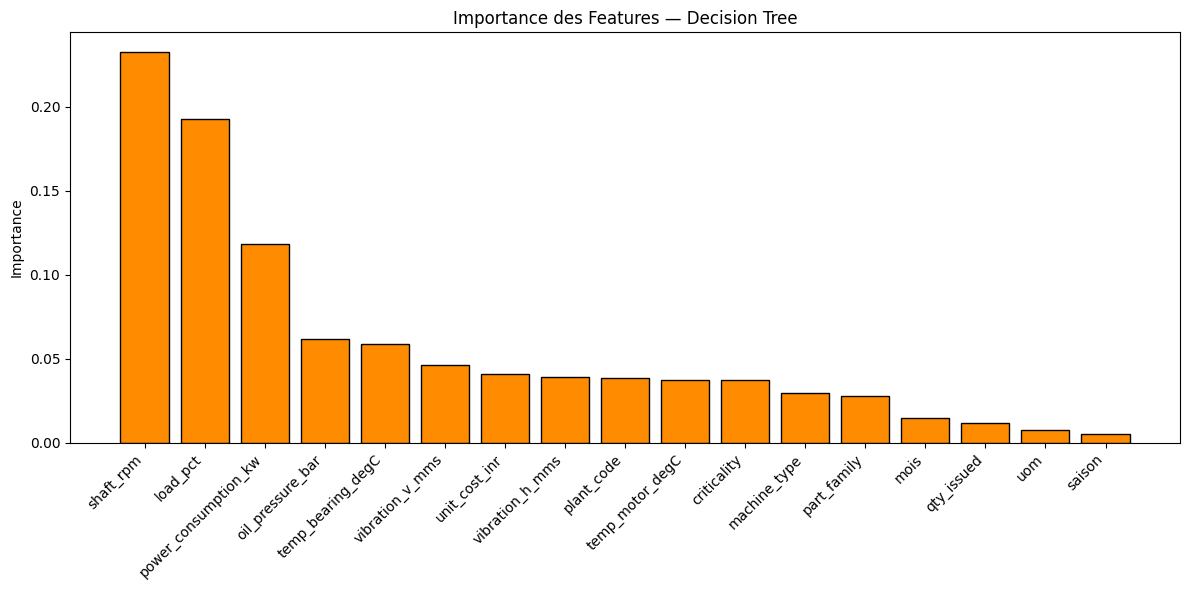

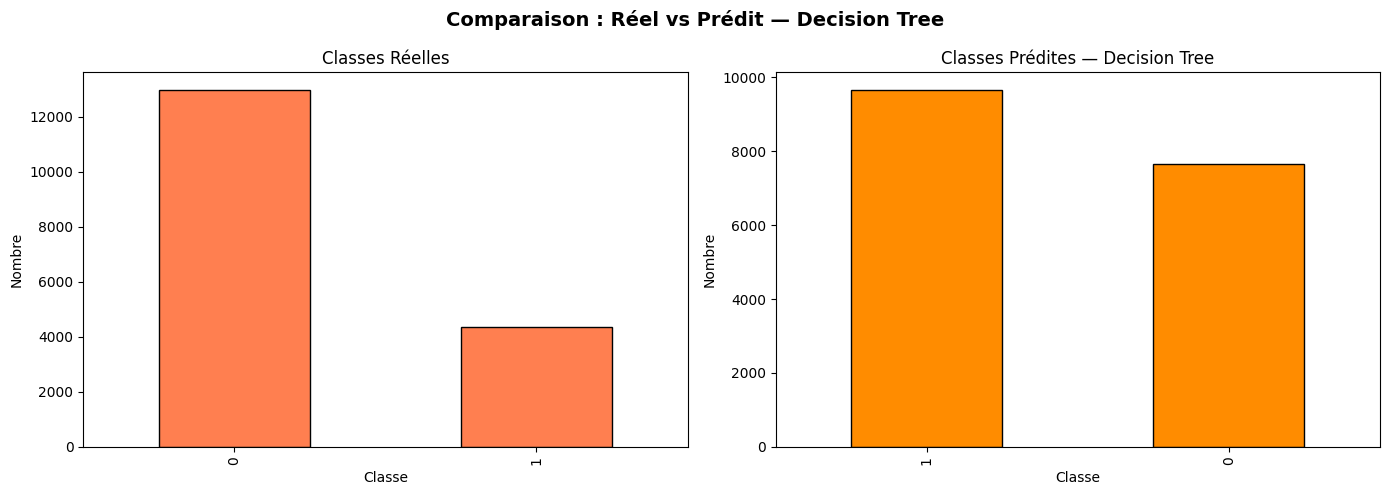

✅ Decision Tree terminé !


In [ ]:

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ██████████████████  DECISION TREE  █████████████████████████████
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# Rapide

# CELLULE 13 — Trouver la meilleure profondeur (avec balanced)

print("🔍 Recherche de la meilleure profondeur...")
liste_depth = range(1, 16)
accs_d = []
for d in liste_depth:
    m = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)
    m.fit(X_train, y_train)
    accs_d.append(f1_score(y_test, m.predict(X_test), average='weighted'))  # ← f1 au lieu d'accuracy

meilleure_depth = liste_depth[np.argmax(accs_d)]
print(f"✅ Meilleure profondeur : {meilleure_depth}  (F1 = {max(accs_d)*100:.2f}%)")

plt.figure(figsize=(10, 5))
plt.plot(liste_depth, [a*100 for a in accs_d], marker='o', color='darkorange', linewidth=2)
plt.axvline(x=meilleure_depth, color='red', linestyle='--', label=f'Profondeur = {meilleure_depth}')
plt.title("F1-Score selon la profondeur — Decision Tree")
plt.xlabel("max_depth"); plt.ylabel("F1-Score (%)")
plt.xticks(liste_depth); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("choix_depth_dt.png", dpi=150); plt.show()


# CELLULE 14 — Entraîner et évaluer Decision Tree

modele_dt = DecisionTreeClassifier(
    max_depth=meilleure_depth,
    criterion='gini',
    class_weight='balanced',
    random_state=42
)
modele_dt.fit(X_train, y_train)
y_pred_dt = modele_dt.predict(X_test)

acc_dt  = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt, average='weighted')
rec_dt  = recall_score(y_test, y_pred_dt, average='weighted')
f1_dt   = f1_score(y_test, y_pred_dt, average='weighted')

print("=" * 50)
print("    RÉSULTATS DU MODÈLE DECISION TREE")
print("=" * 50)
print(f"  🎯 Accuracy  : {acc_dt  * 100:.2f}%")
print(f"  🔍 Precision : {prec_dt * 100:.2f}%")
print(f"  📡 Recall    : {rec_dt  * 100:.2f}%")
print(f"  ⚖️  F1-Score : {f1_dt   * 100:.2f}%")
print("=" * 50)
print(classification_report(y_test, y_pred_dt))


# CELLULE 15 — Matrice de confusion + Arbre + Importance — DT

cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Matrice de Confusion — Decision Tree', fontsize=13)
plt.xlabel('Classe Prédite'); plt.ylabel('Classe Réelle')
plt.tight_layout(); plt.savefig("matrice_confusion_dt.png", dpi=150); plt.show()

# Visualiser l'arbre
plt.figure(figsize=(20, 10))
plot_tree(modele_dt, feature_names=list(X.columns), class_names=noms_classes,
          filled=True, rounded=True, fontsize=9, impurity=False)
plt.title("Arbre de Décision", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("arbre_decision.png", dpi=150, bbox_inches='tight'); plt.show()

# Importance des features
importances = modele_dt.feature_importances_
indices     = np.argsort(importances)[::-1]
noms_feat   = list(X.columns)
plt.figure(figsize=(12, 6))
plt.bar(range(len(noms_feat)), importances[indices], color='darkorange', edgecolor='black')
plt.xticks(range(len(noms_feat)), [noms_feat[i] for i in indices], rotation=45, ha='right')
plt.title("Importance des Features — Decision Tree"); plt.ylabel("Importance")
plt.tight_layout(); plt.savefig("importance_dt.png", dpi=150); plt.show()


# CELLULE 16 — Réel vs Prédit DT

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(y_test).value_counts().plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Classes Réelles'); axes[0].set_xlabel('Classe'); axes[0].set_ylabel('Nombre')
pd.Series(y_pred_dt).value_counts().plot(kind='bar', ax=axes[1], color='darkorange', edgecolor='black')
axes[1].set_title('Classes Prédites — Decision Tree'); axes[1].set_xlabel('Classe'); axes[1].set_ylabel('Nombre')
plt.suptitle('Comparaison : Réel vs Prédit — Decision Tree', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("comparaison_dt.png", dpi=150); plt.show()
print("✅ Decision Tree terminé !")

Code de l'algorithme Random Forest

🔍 Recherche du meilleur n_estimators...
✅ Meilleur n_estimators : 200  (F1 = 68.10%)


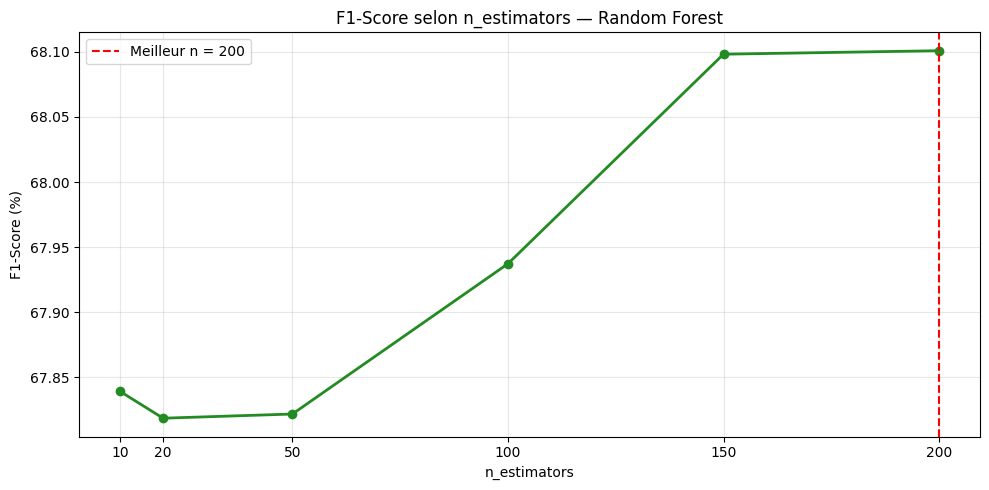

    RÉSULTATS DU MODÈLE RANDOM FOREST
  🎯 Accuracy  : 71.86%
  🔍 Precision : 66.81%
  📡 Recall    : 71.86%
  ⚖️  F1-Score : 68.10%
              precision    recall  f1-score   support

           0       0.77      0.90      0.83     12965
           1       0.38      0.18      0.24      4344

    accuracy                           0.72     17309
   macro avg       0.57      0.54      0.54     17309
weighted avg       0.67      0.72      0.68     17309



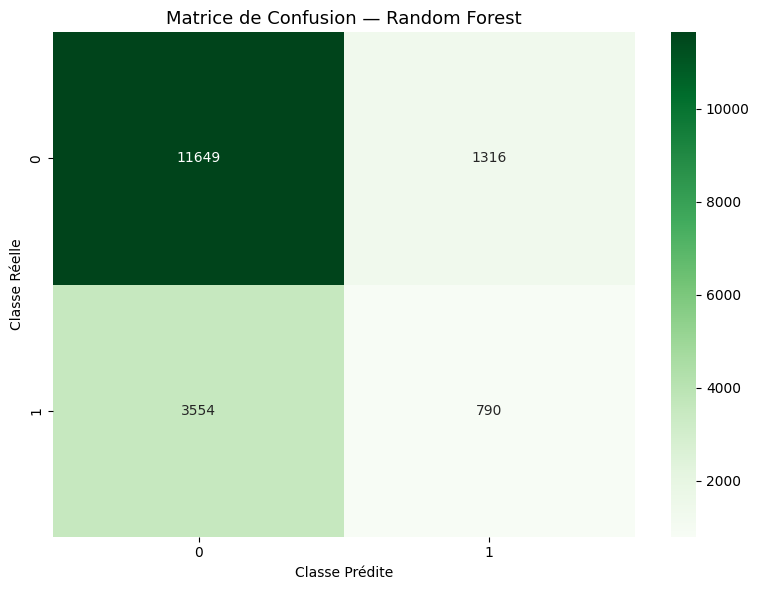

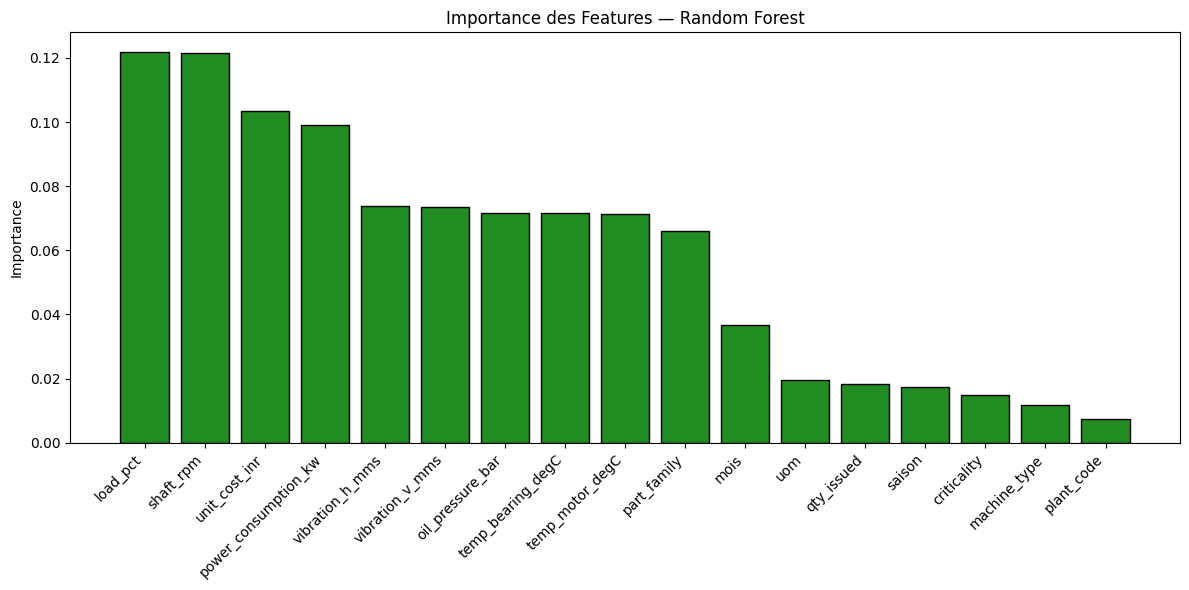

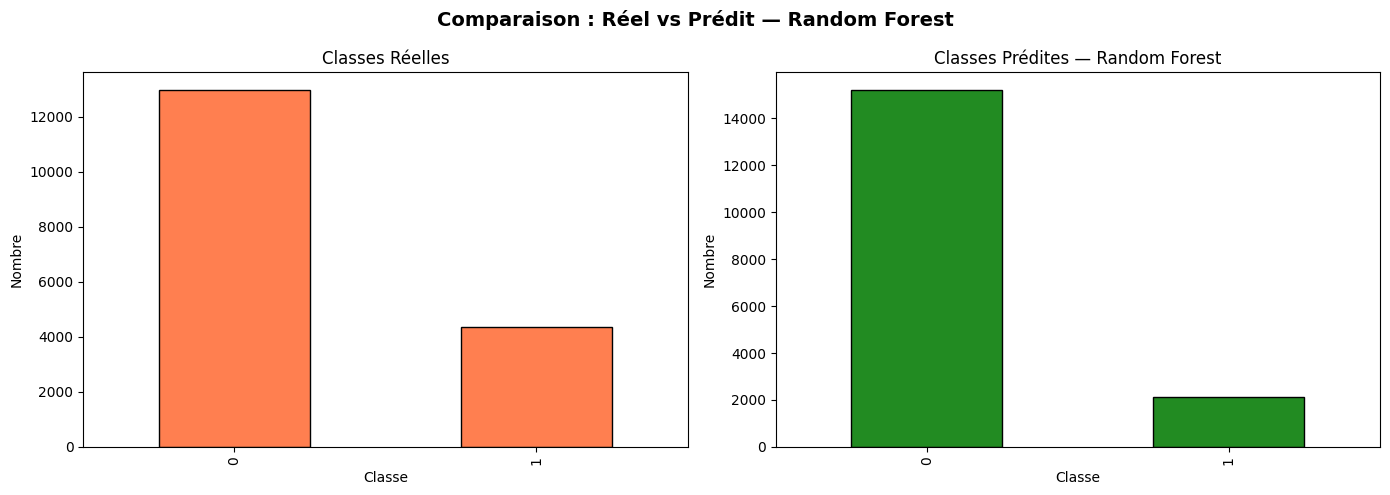

✅ Random Forest terminé !


In [ ]:

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ██████████████████  RANDOM FOREST  █████████████████████████████
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# CELLULE 17 — Trouver le meilleur n_estimators (avec balanced)

print("🔍 Recherche du meilleur n_estimators...")
liste_n = [10, 20, 50, 100, 150, 200]
scores_n = []
for n in liste_n:
    m = RandomForestClassifier(n_estimators=n, class_weight='balanced', random_state=42, n_jobs=-1)
    m.fit(X_train, y_train)
    scores_n.append(f1_score(y_test, m.predict(X_test), average='weighted'))  # ← f1 au lieu d'accuracy

meilleur_n = liste_n[np.argmax(scores_n)]
print(f"✅ Meilleur n_estimators : {meilleur_n}  (F1 = {max(scores_n)*100:.2f}%)")

plt.figure(figsize=(10, 5))
plt.plot(liste_n, [s*100 for s in scores_n], marker='o', color='forestgreen', linewidth=2)
plt.axvline(x=meilleur_n, color='red', linestyle='--', label=f'Meilleur n = {meilleur_n}')
plt.title("F1-Score selon n_estimators — Random Forest")
plt.xlabel("n_estimators"); plt.ylabel("F1-Score (%)")
plt.xticks(liste_n); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig("choix_n_rf.png", dpi=150); plt.show()


# CELLULE 18 — Entraîner et évaluer Random Forest

modele_rf = RandomForestClassifier(
    n_estimators=meilleur_n,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
modele_rf.fit(X_train, y_train)
y_pred_rf = modele_rf.predict(X_test)

acc_rf  = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, average='weighted')
rec_rf  = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf   = f1_score(y_test, y_pred_rf, average='weighted')

print("=" * 50)
print("    RÉSULTATS DU MODÈLE RANDOM FOREST")
print("=" * 50)
print(f"  🎯 Accuracy  : {acc_rf  * 100:.2f}%")
print(f"  🔍 Precision : {prec_rf * 100:.2f}%")
print(f"  📡 Recall    : {rec_rf  * 100:.2f}%")
print(f"  ⚖️  F1-Score : {f1_rf   * 100:.2f}%")
print("=" * 50)
print(classification_report(y_test, y_pred_rf))


# CELLULE 19 — Matrice de confusion + Importance — RF

cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Matrice de Confusion — Random Forest', fontsize=13)
plt.xlabel('Classe Prédite'); plt.ylabel('Classe Réelle')
plt.tight_layout(); plt.savefig("matrice_confusion_rf.png", dpi=150); plt.show()

importances_rf = modele_rf.feature_importances_
indices_rf     = np.argsort(importances_rf)[::-1]
plt.figure(figsize=(12, 6))
plt.bar(range(len(noms_feat)), importances_rf[indices_rf], color='forestgreen', edgecolor='black')
plt.xticks(range(len(noms_feat)), [noms_feat[i] for i in indices_rf], rotation=45, ha='right')
plt.title("Importance des Features — Random Forest"); plt.ylabel("Importance")
plt.tight_layout(); plt.savefig("importance_rf.png", dpi=150); plt.show()


# CELLULE 20 — Réel vs Prédit RF

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(y_test).value_counts().plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Classes Réelles'); axes[0].set_xlabel('Classe'); axes[0].set_ylabel('Nombre')
pd.Series(y_pred_rf).value_counts().plot(kind='bar', ax=axes[1], color='forestgreen', edgecolor='black')
axes[1].set_title('Classes Prédites — Random Forest'); axes[1].set_xlabel('Classe'); axes[1].set_ylabel('Nombre')
plt.suptitle('Comparaison : Réel vs Prédit — Random Forest', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("comparaison_rf.png", dpi=150); plt.show()
print("✅ Random Forest terminé !")


Code de l'algorithme ANN

🧠 ANN : 17 features → 128 → 64 → 32 → 2 classes


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,706 (49.63 KB)

 Trainable params: 12,706 (49.63 KB)

 Non-trainable params: 0 (0.00 B)

🤖 Entraînement ANN en cours...
Epoch 1/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.6870 - loss: 0.7774 - val_accuracy: 0.6651 - val_loss: 0.5629
Epoch 2/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.6799 - loss: 0.7440 - val_accuracy: 0.6917 - val_loss: 0.5439
Epoch 3/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.6836 - loss: 0.7355 - val_accuracy: 0.6878 - val_loss: 0.5358
Epoch 4/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6823 - loss: 0.7313 - val_accuracy: 0.7097 - val_loss: 0.5257
Epoch 5/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.6853 - loss: 0.7286 - val_accuracy: 0.6818 - val_loss: 0.5471
Epoch 6/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.6880 - loss: 0.7271 - val_accuracy: 0.6505 - val_loss: 0.5501
Epoch 7/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6838 - loss: 0.7260 - val_accuracy: 0.6840 - val_loss: 0.5350
Epoch 8/50
1948/1948 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - a

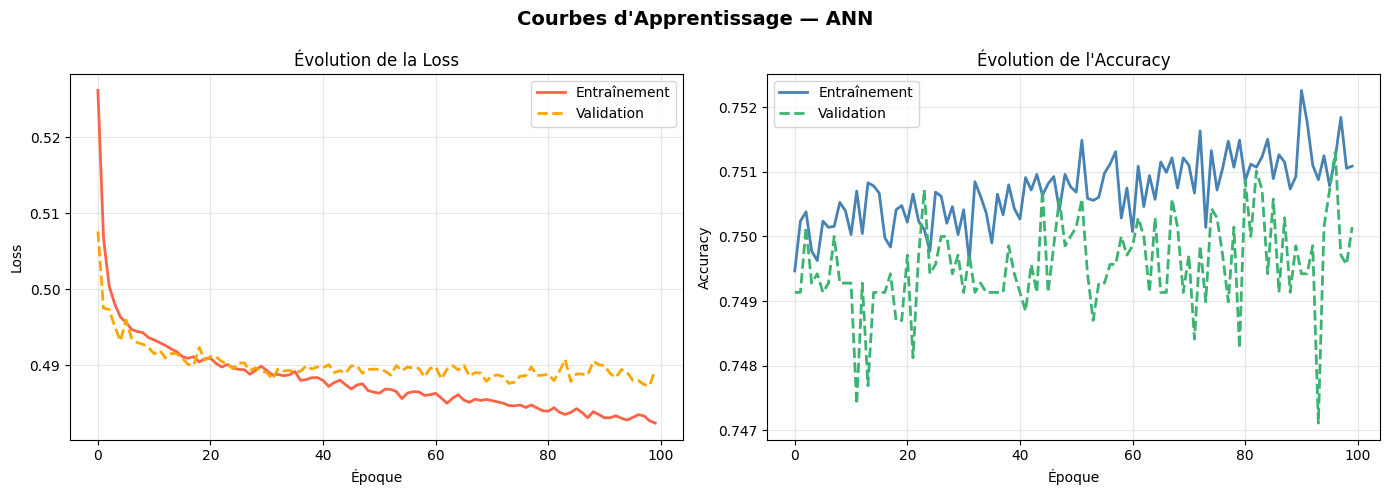

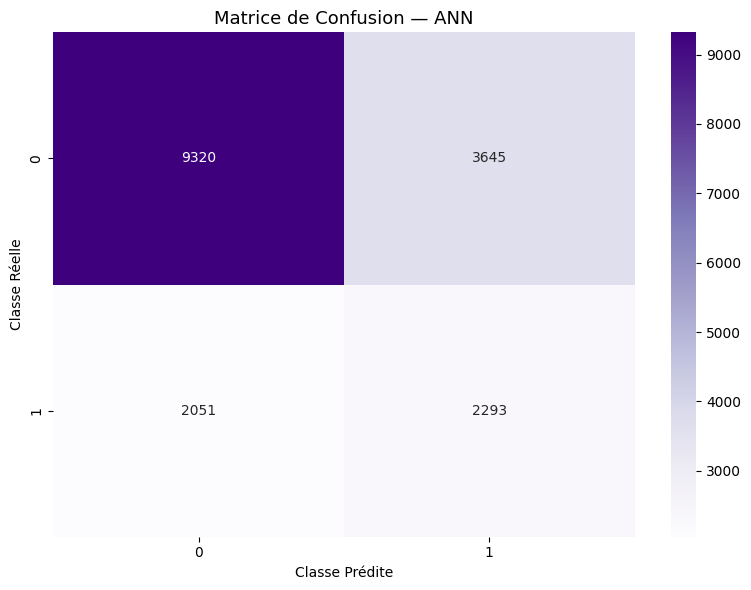

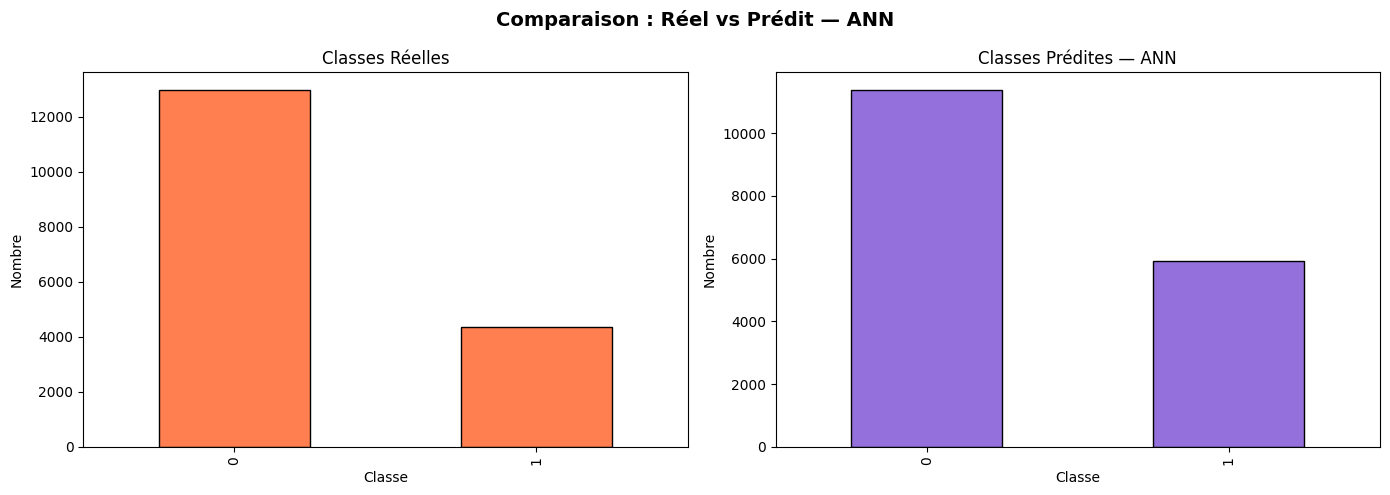

✅ ANN terminé !


In [ ]:

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ████████████████████  ANN  █████████████████████████████████████
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# CELLULE 21 — Construire et entraîner l'ANN

import tensorflow as tf

nb_features = X_train_sc.shape[1]
print(f"🧠 ANN : {nb_features} features → 128 → 64 → 32 → {nb_classes} classes")

# Poids des classes pour compenser le déséquilibre
class_weights = {0: 1.0, 1: 2.0}   # ← pénaliser plus les erreurs sur les pannes

modele_ann = Sequential([
    Dense(128, activation='relu', input_shape=(nb_features,)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(nb_classes, activation='softmax')
])

modele_ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modele_ann.summary()

print("🤖 Entraînement ANN en cours...")
history = modele_ann.fit(
    X_train_sc, y_train_cat,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    class_weight=class_weights,  # ← ajout ici
    verbose=1
)
print("✅ ANN entraîné avec succès !")


# CELLULE 22 — Évaluer ANN

y_pred_ann = np.argmax(modele_ann.predict(X_test_sc), axis=1)

acc_ann  = accuracy_score(y_test, y_pred_ann)
prec_ann = precision_score(y_test, y_pred_ann, average='weighted')
rec_ann  = recall_score(y_test, y_pred_ann, average='weighted')
f1_ann   = f1_score(y_test, y_pred_ann, average='weighted')

print("=" * 50)
print("       RÉSULTATS DU MODÈLE ANN")
print("=" * 50)
print(f"  🎯 Accuracy  : {acc_ann  * 100:.2f}%")
print(f"  🔍 Precision : {prec_ann * 100:.2f}%")
print(f"  📡 Recall    : {rec_ann  * 100:.2f}%")
print(f"  ⚖️  F1-Score : {f1_ann   * 100:.2f}%")
print("=" * 50)
print(classification_report(y_test, y_pred_ann))


# CELLULE 23 — Courbes d'apprentissage + Matrice ANN

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(historique.history['loss'], label='Entraînement', color='tomato', linewidth=2)
axes[0].plot(historique.history['val_loss'], label='Validation', color='orange', linewidth=2, linestyle='--')
axes[0].set_title("Évolution de la Loss"); axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(historique.history['accuracy'], label='Entraînement', color='steelblue', linewidth=2)
axes[1].plot(historique.history['val_accuracy'], label='Validation', color='mediumseagreen', linewidth=2, linestyle='--')
axes[1].set_title("Évolution de l'Accuracy"); axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Accuracy")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.suptitle("Courbes d'Apprentissage — ANN", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("courbes_ann.png", dpi=150); plt.show()

cm_ann = confusion_matrix(y_test, y_pred_ann)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_ann, annot=True, fmt='d', cmap='Purples',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Matrice de Confusion — ANN', fontsize=13)
plt.xlabel('Classe Prédite'); plt.ylabel('Classe Réelle')
plt.tight_layout(); plt.savefig("matrice_confusion_ann.png", dpi=150); plt.show()


# CELLULE 24 — Réel vs Prédit ANN

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(y_test).value_counts().plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Classes Réelles'); axes[0].set_xlabel('Classe'); axes[0].set_ylabel('Nombre')
pd.Series(y_pred_ann).value_counts().plot(kind='bar', ax=axes[1], color='mediumpurple', edgecolor='black')
axes[1].set_title('Classes Prédites — ANN'); axes[1].set_xlabel('Classe'); axes[1].set_ylabel('Nombre')
plt.suptitle('Comparaison : Réel vs Prédit — ANN', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("comparaison_ann.png", dpi=150); plt.show()
print("✅ ANN terminé !")


 Comparaison des résultats de tous les modèles


         COMPARAISON FINALE — DataPiece.csv
               Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
Algorithme                                                          
SVM                  58.78%         74.22%      58.78%        61.35%
KNN                  57.58%         71.74%      57.58%        60.31%
Decision Tree        57.43%         73.45%      57.43%        60.02%
Random Forest        71.86%         66.81%      71.86%        68.10%
ANN                  67.09%         71.08%      67.09%        68.57%

🏆 Meilleur algorithme (F1-Score) : ANN


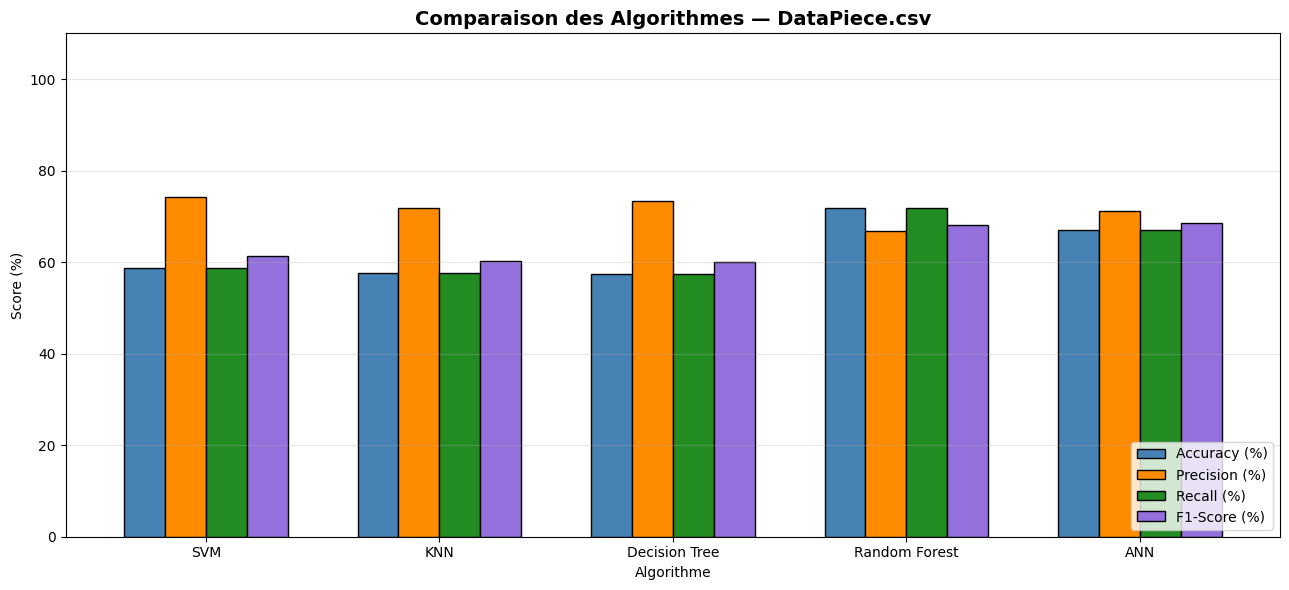

✅ Comparaison finale terminée — Bonne chance ! 🎉


In [ ]:

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# ████████████████  COMPARAISON FINALE  ██████████████████████████
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# CELLULE 25 — Tableau comparatif automatique ✅

resultats = {
    'Algorithme'    : ['SVM', 'KNN', 'Decision Tree', 'Random Forest', 'ANN'],
    'Accuracy (%)'  : [acc_svm*100,  acc_knn*100,  acc_dt*100,  acc_rf*100,  acc_ann*100],
    'Precision (%)' : [prec_svm*100, prec_knn*100, prec_dt*100, prec_rf*100, prec_ann*100],
    'Recall (%)'    : [rec_svm*100,  rec_knn*100,  rec_dt*100,  rec_rf*100,  rec_ann*100],
    'F1-Score (%)'  : [f1_svm*100,   f1_knn*100,   f1_dt*100,   f1_rf*100,   f1_ann*100],
}

df_res = pd.DataFrame(resultats).set_index('Algorithme')

print("\n" + "=" * 70)
print("         COMPARAISON FINALE — DataPiece.csv")
print("=" * 70)
print(df_res.to_string(float_format=lambda x: f"{x:.2f}%"))
print("=" * 70)
print(f"\n🏆 Meilleur algorithme (F1-Score) : {df_res['F1-Score (%)'].idxmax()}")

df_res.plot(kind='bar', figsize=(13, 6),
            color=['steelblue', 'darkorange', 'forestgreen', 'mediumpurple'],
            edgecolor='black', width=0.7)
plt.title("Comparaison des Algorithmes — DataPiece.csv", fontsize=14, fontweight='bold')
plt.xlabel("Algorithme"); plt.ylabel("Score (%)")
plt.xticks(rotation=0); plt.ylim(0, 110)
plt.legend(loc='lower right'); plt.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig("comparaison_finale.png", dpi=150); plt.show()
print("✅ Comparaison finale terminée — Bonne chance ! 🎉")